# I-01: assisted recovery with one fixed Run All

Use a fresh online **T4 x2** session and the matching assisted **i01-source.zip**.
This notebook executes one precommitted condition: eight scalar qualification
controls, four single-call diagnostics, four balanced live pilots, then (only
if eligible) twenty fixed main worlds in ten batches. The two agents receive
one openly disclosed strategy/interface package; retain and clear share it.

The maximum is **480 ordinary physical attempts +20 contingency =500**. All
warmups, failures, diagnostics and eligible retries count. Main eligibility
requires complete pilot evidence, at least **3/4 correct original teams** and
**7/8 correct pilot controls**, current health and an adequate measured forecast.
There is no recovery-success, effect-direction, all-actions-legal or qualitative
message veto. If usefulness fails, preserve a complete feasibility report and
leave main unexecuted. No prompt/model tuning or repeat-until-pass is allowed.

Ordinary main mistakes stay in the fixed population. Scalar/probe success does
not certify live collaboration. Each cell has one finite, idempotent scope;
completed stages spend zero on rerun. Models remain resident through the work.
Setup/downloads consume the same fixed window. The 700-minute planning estimate
is not a provider allowance guarantee; reduce it to the actual time remaining.

Running this notebook is a separate explicit execution request. The software's
CPU checks and design approval alone authorize no inference. Human trace review
remains retrospective and visibly pending. Download every checkpoint and the
executed notebook; a provider may end the session before the final export.


## 1. Fresh-session configuration

Defaults assume a new approximately twelve-hour allocation. Check actual GPU allowance; lower the minutes for any time already elapsed. The evidence note describes an estimate truthfully. Do not copy a previous session deadline or extend the window by rerunning.


In [1]:
RUN_DIR = "/kaggle/working/i01-assisted-study"
SESSION_REMAINING_MINUTES = 700  # Conservative fresh-session estimate; reduce to actual time left.
SESSION_ALLOWANCE_EVIDENCE = "User reports an approximately 12-hour session; 700-minute fresh-session planning bound, provider quota/deadline not independently verified."


## 2. Verify source and inspect the workspace

Only the matching whole-study source release is accepted. Inventory only; no model loading or inference.


In [2]:
from pathlib import Path
import hashlib, json, shutil, sys, tempfile, zipfile

# Select one exact small source attachment. ZIP and Kaggle-expanded roots work.
SOURCE_BUNDLE = None  # Set only if more than one candidate is attached.
source_candidates = list(Path('/kaggle/input').rglob('i01-source.zip'))
source_candidates += [p.parent for p in Path('/kaggle/input').rglob('source-release.json')]
# Expanded old checkpoints carry their own historical source. They are evidence,
# not candidates for this repaired notebook's active source attachment.
def repaired_source_manifest(path):
    try:
        if path.is_dir():
            manifest = json.loads((path/'source-release.json').read_text())
        else:
            with zipfile.ZipFile(path) as archive:
                manifest = json.loads(archive.read('source-release.json'))
        return manifest if manifest.get('execution_policy') == 'i01-assisted-feasibility-2026-10-16' and all('recovery/i01/'+name+'.py' in manifest['files'] for name in ('policy','continuation')) else None
    except (OSError, ValueError, KeyError, zipfile.BadZipFile):
        return None
unique_sources = {}
for candidate in source_candidates:
    manifest = repaired_source_manifest(candidate)
    if manifest:
        identity = (manifest.get('git_head'), json.dumps(manifest['files'], sort_keys=True))
        unique_sources.setdefault(identity, candidate)  # Same ZIP/expanded release is one choice.
source_candidates = list(unique_sources.values())
if SOURCE_BUNDLE is None:
    if len(source_candidates) != 1:
        raise RuntimeError(f'Select SOURCE_BUNDLE explicitly; candidates: {source_candidates}')
    SOURCE_BUNDLE = source_candidates[0]
selected_source = Path(SOURCE_BUNDLE)
with tempfile.TemporaryDirectory(prefix='i01-source-', dir='/kaggle/working') as staging_name:
    staging = Path(staging_name)
    if selected_source.is_file():
        with zipfile.ZipFile(selected_source) as source_zip:
            infos = source_zip.infolist()
            if sum(p.file_size for p in infos) > 64 * 2**20 or len({p.filename for p in infos}) != len(infos):
                raise RuntimeError('Source attachment size or duplicate member violation')
            for item in infos:
                p = Path(item.filename)
                if p.is_absolute() or '..' in p.parts or '\\' in item.filename or ':' in item.filename or ((item.external_attr >> 16) & 0o170000) == 0o120000:
                    raise RuntimeError('Unsafe source archive member')
            if source_zip.testzip() is not None:
                raise RuntimeError('Source ZIP integrity failed')
            source_zip.extractall(staging)
    elif selected_source.is_dir():
        if any(p.is_symlink() for p in selected_source.rglob('*')):
            raise RuntimeError('Select an ordinary verified expanded source directory')
        shutil.copytree(selected_source, staging, dirs_exist_ok=True)
    else:
        raise RuntimeError('Missing exact selected source attachment')
    release = json.loads((staging/'source-release.json').read_text())
    if release['format'] != 'i01-online-source-v1':
        raise RuntimeError('Wrong source release format')
    if release.get('execution_policy') != 'i01-assisted-feasibility-2026-10-16' or not all('recovery/i01/'+name+'.py' in release['files'] for name in ('policy','continuation')):
        raise RuntimeError('This notebook requires the whole-study Run All source packet; preserve old checkpoints and replace the active source attachment.')
    head = release.get('git_head', '')
    if len(head) != 40 or any(c not in '0123456789abcdef' for c in head):
        raise RuntimeError('Invalid source release commit')
    source_root = Path('/kaggle/working') / ('i01-source-' + head[:12])
    for relative, wanted in release['files'].items():
        path = staging/relative
        if not path.is_file() or path.stat().st_size != wanted['bytes'] or hashlib.sha256(path.read_bytes()).hexdigest() != wanted['sha256']:
            raise RuntimeError(f'Source identity failed: {relative}')
        if source_root.exists() and (not (source_root/relative).is_file() or hashlib.sha256((source_root/relative).read_bytes()).hexdigest() != wanted['sha256']):
            raise RuntimeError('Existing source differs; select a fresh session/source directory')
    if not source_root.exists():
        shutil.copytree(staging, source_root)
loaded_source = sys.modules.get('recovery')
if loaded_source is not None and not Path(loaded_source.__file__).resolve().is_relative_to(source_root.resolve()):
    raise RuntimeError('Restart the notebook kernel before using this source release; saved study files are preserved.')
sys.path.insert(0, str(source_root))
from recovery.i01.notebook import Study
if 'study' not in globals():
    study = Study(source_root, run=RUN_DIR, assisted=True)
elif study.source.resolve()!=source_root.resolve() or study.run_dir.resolve()!=Path(RUN_DIR).resolve() or not study.assisted:
    raise RuntimeError('Finish the current study and restart the kernel before changing source or RUN_DIR; existing study files are preserved.')
study.bootstrap_status()


Workspace,Observed value
Python,"3.13.15 (main, Aug 6 2026, 11:06:22) [GCC 13.3.0]"
System,Linux
Source,/kaggle/working/i01-source-d95bb0122359
Study files,/kaggle/working/i01-assisted-study


Device,Model,UUID,Memory (MiB)
0,Tesla T4,GPU-ae83229f-4ac3-bcc2-ee15-78dbe97ec4cb,15360
1,Tesla T4,GPU-07305445-0160-a56e-369f-674eb80fbd9a,15360


Storage,Path,Free GiB
scratch,/kaggle/temp/i01,1069.91
working,/kaggle/working,19.5


Session window: unset; preparation is available, model loading requires actual facts in its dedicated cell.
Next: run Install the pinned runtime. Host acceptance still occurs before installation.


## 3. Record the fixed execution window

Record BEFORE installation and downloads. Reruns retain this deadline. No provider assignment, quota or release is inferred from the configured planning window.


In [3]:
study.configure_session(remaining_minutes=SESSION_REMAINING_MINUTES,
    evidence=SESSION_ALLOWANCE_EVIDENCE, basis="planning_estimate");


Measurement,Recorded value
Deadline,2026-10-17T01:56:26.794802+00:00
Evidence,"User reports an approximately 12-hour session; 700-minute fresh-session planning bound, provider quota/deadline not independently verified."
Apply after initialization,Yes


## 4. Install the pinned runtime

Verified pip bootstrap without ensurepip, unchanged pinned dependencies, isolated/headless controller, visible logs/progress. No host startup hooks or unpinned upgrades.


In [4]:
study.install_runtime();


Setup: venv
Setup: download verified pip bootstrap wheel
Setup: bootstrap-pip
Setup: pip-isolation
Setup: dependencies
dependencies: 15s elapsed;   Downloading nvidia_cudnn_cu12-9.19.0.56-py3-none-manylinux_2_27_x86_64.whl (657.9 MB)
dependencies: 30s elapsed;      ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 288.2/288.2 MB 190.8 MB/s  0:00:01
dependencies: 45s elapsed;   Downloading torch-2.11.0%2Bcu128-cp313-cp313-manylinux_2_28_x86_64.whl (820.3 MB)
dependencies: 60s elapsed;   Downloading torch-2.11.0%2Bcu128-cp313-cp313-manylinux_2_28_x86_64.whl (820.3 MB)
dependencies: 75s elapsed; py, anyio, rich, requests-toolbelt, pydantic, nvidia-cusolver-cu12, matplotlib, httpx2, httpx, typer, langsmith, torch, langchain-core, huggingface-hub, tokenizers, langgraph-sdk, langgraph-checkpoint, bitsandbytes, accelerate, transformers, langgraph-prebuilt, langgraph-checkpoint-sqlite, langgraph
dependencies: 90s elapsed; py, anyio, rich, requests-toolbelt, pydantic, nvidia-cusolver-cu12, matplotlib, h

Measurement,Recorded value
Interpreter,/kaggle/temp/i01/i01-venv-d95bb0122359/bin/python
Source,/kaggle/working/i01-source-d95bb0122359
Scratch,/kaggle/temp/i01
Working,/kaggle/working
Hf cache,/kaggle/temp/i01/hf-cache
Setup seconds,174.92810445100002
Model attempts,0


## 5. Start the independent study

New study at zero, no old checkpoint/result import. Repeating this cell reuses the same destination and preserves spending; an old shared campaign cannot be converted.


In [5]:
study.start_new();


Measurement,Recorded value
Deadline,2026-10-17T01:56:26.794802+00:00
Evidence,"User reports an approximately 12-hour session; 700-minute fresh-session planning bound, provider quota/deadline not independently verified."
Apply after initialization,Yes


session: recorded in the stage receipt
Checkpoint action/window: 1,697,748 bytes; integrity passed
window: complete · checkpoint /kaggle/working/i01-assisted-study/exports/latest.zip
Checkpoint study-open: 1,697,949 bytes; integrity passed
snapshot: complete · checkpoint /kaggle/working/i01-assisted-study/exports/latest.zip


Measurement,Recorded value
Attempt scope,independent-study
Attempts,0
Attempts unknown generated tokens,0
Attempts unknown input tokens,0
Attempts unknown ready seconds,0
Campaign attempts,0
Campaign attempts unknown ready seconds,0
Campaign generated tokens observed,0
Campaign ready seconds observed,0
Clear minus retain,Unknown / not recorded


Main coverage,Value
Known paired outcomes,0 / 20
Campaign physical attempts,0 / 500 (0 here)
Clear minus retain,Unknown / not recorded
Unknown-outcome bounds,"[-1.0, 1.0]"


Logical slot,Resident,Load receipt
0,No,Not recorded
1,No,Not recorded


Budget,Value
attempt scope,independent-study
attempts,0
campaign attempts,0
contingency,0
in flight,0
local contingency,0
lost spending,"{'resolved': True, 'upper': 0}"
missing prior studies,[]
prior attempts,0
prior spending pending,Unknown / not recorded


## 6. Check implementation and native tokenizer

Focused scripted math/private-view/lifecycle/accounting/durability/archive checks and native token bounds. Zero model attempts.


In [6]:
study.check_implementation();


Checkpoint action/selfcheck: 1,771,009 bytes; integrity passed
selfcheck: complete · checkpoint /kaggle/working/i01-assisted-study/exports/latest.zip


Measurement,Recorded value
Environment,scripted temporary DBs; no model loaded
Executed at,2026-10-16T14:19:40.442664+00:00
Model attempts,0
Native tokenizer,Yes
Passed,Yes


Lightweight check,State
native fixture 827/revised 780; duplicates/negative/boundary,Passed
fixed strata/seeds; private views; finality/wait; literal siblings; invalid actions,Passed
raw-before-effects; idempotence; pre-persistence retry; 499/500; backup/ZIP/expanded restore; unknown vs zero,Passed
exact new-input separation from locally exposed Course-1..7 and saved fixtures,Passed


Native tokenizer: passed


Checkpoint: passed


## 7. Download and verify weights

Pinned model snapshot and actual storage/native file checks. Scratch caches are reused when valid.


In [7]:
study.download_weights();


Setup: weights-command
weights-command: 15s elapsed; Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
weights-command: 75s elapsed; Fetching 12 files:  50%|█████     | 6/12 [01:11<01:11, 11.85s/it]
weights-command: 90s elapsed; Verifying pinned native bytes 4/12: model.safetensors-00001-of-00004.safetensors (5,276,436,216 bytes)
weights-command: 105s elapsed; Verifying pinned native bytes 4/12: model.safetensors-00001-of-00004.safetensors (5,276,436,216 bytes)
weights-command: 120s elapsed; Verifying pinned native bytes 5/12: model.safetensors-00002-of-00004.safetensors (5,335,161,512 bytes)
weights-command: 135s elapsed; Verifying pinned native bytes 6/12: model.safetensors-00003-of-00004.safetensors (5,368,717,440 bytes)
weights-command: 150s elapsed; Verifying pinned native bytes 7/12: model.safetensors-00004-of-00004.safetensors (3,325,99

Measurement,Recorded value
Model,Qwen/Qwen3.5-9B
Revision,c202236235762e1c871ad0ccb60c8ee5ba337b9a
Snapshot,/kaggle/temp/i01/hf-cache/models--Qwen--Qwen3.5-9B/snapshots/c202236235762e1c871ad0ccb60c8ee5ba337b9a
Native total bytes,19329302519
Weights,Yes
Model attempts,0


## 8. Load both resident T4 workers

Two fixed replicas; concise actual load/device evidence. Loading generates no hidden warmup. Inspection and research stages retain these replicas.


In [8]:
study.load_models();


Working · 45s · Loading weights:  77%|███████▋  | 327/427 [00:32<00:08, 12.32it/s]
Working · 60s · Model load: audit actual tensors, quantization and loading diagnostics
Working · 90s · Loading weights:  93%|█████████▎| 395/427 [00:22<00:00, 37.05it/s]
Checkpoint action/load: 1,832,645 bytes; integrity passed
load: complete · checkpoint /kaggle/working/i01-assisted-study/exports/latest.zip


Logical slot,CUDA UUID,Load seconds,Total device GiB
0,ae83229f-4ac3-bcc2-ee15-78dbe97ec4cb,56.451797188,14.56
1,07305445-0160-a56e-369f-674eb80fbd9a,33.79610314700005,14.56


Logical slot,Model / revision,Attention,Recurrent fast path
0,Qwen/Qwen3.5-9B / c202236235762e1c871ad0ccb60c8ee5ba337b9a,recovery_t4_sdpa,No
1,Qwen/Qwen3.5-9B / c202236235762e1c871ad0ccb60c8ee5ba337b9a,recovery_t4_sdpa,No


Pinned text-only NF4/FP16 replicas accepted by the reviewed loader. The loading-only generation profile is not the per-call I-01 profile: direct uses 512 output tokens, temperature 0.7/top-p 0.8/top-k 20.
Known upstream documentation/deprecation messages and optional recurrent-kernel fallback are retained in controller-stderr.log. Full load/tensor inventories remain in sessions.csv and the checkpoint; no runtime upgrade is applied.
Checkpoint: passed


## 9. Lock the complete execution plan

Before the first model call, bind the unchanged manifest/settings, objective checks, ten fixed batches and retrospective review policy. Pilots cannot tune this configuration.


In [9]:
study.plan_execution();


Checkpoint action/plan_execution: 1,901,406 bytes; integrity passed
plan_execution: complete · checkpoint /kaggle/working/i01-assisted-study/exports/latest.zip


Measurement,Recorded value
At,2026-10-16T14:23:59.194530+00:00
External download verified,No
Human review,retrospective_pending
Human understanding verified,No
Main admission,four complete pilots; original teams >=3/4; pilot scalar controls >=7/8; intact current health/resources; no recovery-effect gate
Main batches,10
Mode,direct
Pilot admission,all four terminal pilot scopes; ordinary mistakes retained
Policy,i01-assisted-feasibility-2026-10-16
Useful communication,Unknown / not recorded


Checkpoint: passed


## 10. Check fresh-state readiness

Six A/B/A calls. Cache/numerical/provider faults or unexplained unequal A/B/A stop; no automatic waiver or extra samples.


In [10]:
study.check_readiness();


hardware/state-0-A1 · GPU slot 0 · attempt 1 · campaign 1/500 (1 here)
Raw saved: hardware/state-0-A1 · 14 tokens · 3.8886540999999397 ready-model seconds
hardware/state-0-B · GPU slot 0 · attempt 2 · campaign 2/500 (2 here)
Raw saved: hardware/state-0-B · 16 tokens · 2.22027105199993 ready-model seconds
hardware/state-0-A2 · GPU slot 0 · attempt 3 · campaign 3/500 (3 here)
Raw saved: hardware/state-0-A2 · 14 tokens · 1.7682180479999943 ready-model seconds
hardware/state-1-A1 · GPU slot 1 · attempt 1 · campaign 4/500 (4 here)
Raw saved: hardware/state-1-A1 · 14 tokens · 2.824958039999956 ready-model seconds
hardware/state-1-B · GPU slot 1 · attempt 2 · campaign 5/500 (5 here)
Raw saved: hardware/state-1-B · 16 tokens · 2.239141880000034 ready-model seconds
hardware/state-1-A2 · GPU slot 1 · attempt 3 · campaign 6/500 (6 here)
Raw saved: hardware/state-1-A2 · 14 tokens · 1.7215759780000326 ready-model seconds
Working · 15s · Inference pid=374 device=1 seed=6249057545533736763 phase=deco

Measurement,Recorded value
Equality policy,Diagnostic: unexpected differences require explicit state-isolation review before qualification; no extra samples or decoding changes.
Needs review,No
Passed,Yes
Reload,No
Session,7785ff79-9fb0-47c3-bedf-b47406d709af


Slot,Probe,Raw visible reply,Finite score steps,Fresh cache
0,A1,"{""message"":null,""submit"":3,""wait"":false}",14,Yes
0,B,"{""message"":null,""submit"":100,""wait"":false}",16,Yes
0,A2,"{""message"":null,""submit"":3,""wait"":false}",14,Yes
1,A1,"{""message"":null,""submit"":3,""wait"":false}",14,Yes
1,B,"{""message"":null,""submit"":100,""wait"":false}",16,Yes
1,A2,"{""message"":null,""submit"":3,""wait"":false}",14,Yes


A/B/A equal by slot: [True, True]; Diagnostic: unexpected differences require explicit state-isolation review before qualification; no extra samples or decoding changes.


Checkpoint: passed


## Qualify the eight direct controls

All eight fixed qualification actions must be legal and committed. Scalar accuracy here is diagnostic; no resampling.


In [11]:
study.qualify_direct();


qualification-00/control-original-direct · GPU slot 0 · attempt 4 · campaign 7/500 (7 here)
Raw saved: qualification-00/control-original-direct · 16 tokens · 2.9311222970000017 ready-model seconds
qualification-00/control-revised-direct · GPU slot 0 · attempt 5 · campaign 8/500 (8 here)
Raw saved: qualification-00/control-revised-direct · 16 tokens · 2.293269384999917 ready-model seconds
qualification-01/control-original-direct · GPU slot 1 · attempt 4 · campaign 9/500 (9 here)
Raw saved: qualification-01/control-original-direct · 16 tokens · 2.5999971439999854 ready-model seconds
qualification-01/control-revised-direct · GPU slot 1 · attempt 5 · campaign 10/500 (10 here)
Raw saved: qualification-01/control-revised-direct · 16 tokens · 2.319183356999929 ready-model seconds
qualification-02/control-original-direct · GPU slot 0 · attempt 6 · campaign 11/500 (11 here)
Raw saved: qualification-02/control-original-direct · 16 tokens · 2.0767657110000073 ready-model seconds
qualification-02/

Measurement,Recorded value
Admitted,8
Attempts unknown effort,0
Committed,8
Correct,8
Generated tokens observed,128
Mode,direct
Passed,Yes
Physical attempts,8
Planned,8
Policy,i01-direct-protocol-2026-10-15


Protocol qualification: 8/8 committed; 0 invalid actions; current eligible: True. Mathematical diagnostic: 8/8.
Original saved gate decision (unchanged): True; rule i01-direct-protocol-2026-10-15


Failed call,Truth,Submission,Error


Checkpoint: passed


## Inspect qualification

Four qualification worlds, eight planned controls; complete raw evidence, accuracy, legality and unknown coverage.


In [12]:
study.inspect_qualification(mode="direct");


Scientific gate: pending; no recorded blocking failure


Mode,Committed/planned,Correct,Wrong scalar,Invalid,Unexecuted,Current eligible,Historical passed
direct,8/8,8,0,0,0,Yes,Yes


Call,Truth,Submission,Valid,Correct,Error,Tokens,Ready seconds
qualification-00/control-original-direct,964,964,Yes,1,Unknown / not recorded,16,2.9311222970000017
qualification-00/control-revised-direct,937,937,Yes,1,Unknown / not recorded,16,2.293269384999917
qualification-01/control-original-direct,943,943,Yes,1,Unknown / not recorded,16,2.5999971439999854
qualification-01/control-revised-direct,925,925,Yes,1,Unknown / not recorded,16,2.319183356999929
qualification-02/control-original-direct,987,987,Yes,1,Unknown / not recorded,16,2.0767657110000073
qualification-02/control-revised-direct,986,986,Yes,1,Unknown / not recorded,16,2.037454188999959
qualification-03/control-original-direct,929,929,Yes,1,Unknown / not recorded,16,2.322305416000063
qualification-03/control-revised-direct,907,907,Yes,1,Unknown / not recorded,16,2.258319840000013


Main paired coverage: 0/20 intended worlds. Campaign: 14/500 physical attempts (14 here, 0 prior); contingency including prior charges/gaps: 0/20. Historical 45 remain separate.


Call,Committed,Legal,Target occurred,Private expected value
qualification-00/diagnostic-D00,No,Unknown / not recorded,Unknown / not recorded,ready
qualification-01/diagnostic-D01,No,Unknown / not recorded,Unknown / not recorded,943
qualification-03/diagnostic-D02,No,Unknown / not recorded,Unknown / not recorded,907
qualification-02/diagnostic-D03,No,Unknown / not recorded,Unknown / not recorded,986


Decision,Observed
Correct original teams,0/4; require 3
Correct pilot controls,0/8; require 7
Complete pilot evidence,No
Usefulness passed,No


Admission resource,Value
Remaining attempt allowance,486
Contingency including bounded lost spending,0
Lost spending evidence,"{'resolved': True, 'upper': 0}"
Remaining session seconds,41504.778469


Exact failed call,Phase,Reason,Admission blocking


Showing 3/8 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## 13. Check full headroom

Two full-input/full-output diagnostic probes, one per current load. Require at least 1.5 GiB measured free headroom on each T4.


In [13]:
study.check_headroom();


hardware/envelope-direct-0 · GPU slot 0 · attempt 8 · campaign 15/500 (15 here)
Working · 15s · Inference pid=360 device=0 seed=8319311398067554287 phase=decode elapsed=13.5s input=8192/8192 decode=0/512 peak_reserved_mib=7828.0
Working · 30s · Inference pid=360 device=0 seed=8319311398067554287 phase=decode elapsed=28.6s input=8192/8192 decode=142/512 peak_reserved_mib=7828.0
Working · 45s · Inference pid=360 device=0 seed=8319311398067554287 phase=decode elapsed=43.6s input=8192/8192 decode=283/512 peak_reserved_mib=7828.0
Working · 60s · Inference pid=360 device=0 seed=8319311398067554287 phase=decode elapsed=58.6s input=8192/8192 decode=425/512 peak_reserved_mib=7828.0
Raw saved: hardware/envelope-direct-0 · 512 tokens · 67.76125604599997 ready-model seconds
hardware/envelope-direct-1 · GPU slot 1 · attempt 8 · campaign 16/500 (16 here)
Working · 75s · Inference pid=374 device=1 seed=4135206465507834163 phase=prefill elapsed=0.0s input=0/8192 decode=0/512 peak_reserved_mib=7538.0
W

Measurement,Recorded value
Mode,direct
Passed,Yes
Reload,No
Session,7785ff79-9fb0-47c3-bedf-b47406d709af


Slot,Generated tokens,Observed free headroom (GiB),Failure
0,512,6.784,None recorded
1,512,6.786,None recorded


Checkpoint: passed


## Run four supplied-view diagnostics

D00–D03 once each. Record actual target actions; nonpasses do not veto main or tune the fixed candidate. Scripted histories are diagnostic fixtures, not naturally generated collaboration.


In [14]:
study.run_diagnostics();


qualification-00/diagnostic-D00 · GPU slot 0 · attempt 9 · campaign 17/500 (17 here)
Raw saved: qualification-00/diagnostic-D00 · 71 tokens · 9.150433773000032 ready-model seconds
qualification-01/diagnostic-D01 · GPU slot 1 · attempt 9 · campaign 18/500 (18 here)
Working · 15s · Inference pid=374 device=1 seed=7305758622257457475 phase=decode elapsed=2.1s input=898/898 decode=0/512 peak_reserved_mib=7826.0
Raw saved: qualification-01/diagnostic-D01 · 49 tokens · 7.05500917300003 ready-model seconds
qualification-03/diagnostic-D02 · GPU slot 1 · attempt 10 · campaign 19/500 (19 here)
Raw saved: qualification-03/diagnostic-D02 · 21 tokens · 4.378596254000058 ready-model seconds
qualification-02/diagnostic-D03 · GPU slot 0 · attempt 10 · campaign 20/500 (20 here)
Raw saved: qualification-02/diagnostic-D03 · 16 tokens · 3.561462560999985 ready-model seconds
Checkpoint action/diagnostics: 2,057,835 bytes; integrity passed
diagnostics: complete · checkpoint /kaggle/working/i01-assisted-stud

Measurement,Recorded value
Complete,Yes
Note,Single-call supplied-view diagnostics; no aggregate success gate or live-competence claim
Policy,i01-assisted-feasibility-2026-10-16


Call,Legal action,Target action occurred,Private expected value
qualification-00/diagnostic-D00,Yes,No,ready
qualification-01/diagnostic-D01,Yes,Yes,943
qualification-03/diagnostic-D02,Yes,No,907
qualification-02/diagnostic-D03,Yes,No,986


Checkpoint: passed


## Verify the preparation checkpoint

Quiescent portable export after diagnostics; actual measured export cost is required before admitting pilots.


In [15]:
study.save_checkpoint(verify=True);


Checkpoint action/snapshot: 2,057,866 bytes; integrity passed
snapshot: complete · checkpoint /kaggle/working/i01-assisted-study/exports/latest.zip


Measurement,Recorded value
Boundary requested,operator-snapshot


Checkpoint: passed


Measurement,Recorded value
Integrity,passed
Attempts,20
Boundary,action/snapshot
Reconstruction,exact outcomes/costs/traces/gates match archived analysis
Model attempts,0


## Run pilot 1

Pilot 1 only: prefix, literal retain/clear siblings and original/revised controls, at most twenty first attempts. Conversation and cumulative checkpoint appear automatically. No outcome-based replacement or extra seed.


In [16]:
study.run_pilot(1);


pilot-00/prefix/agent-0/invocation-0 · GPU slot 0 · attempt 11 · campaign 21/500 (21 here)
Raw saved: pilot-00/prefix/agent-0/invocation-0 · 36 tokens · 5.635019796999927 ready-model seconds
pilot-00 / prefix / agent 0: {'message': "My local max is 938 at record 18. I will wait for agent 1's report.", 'submit': None, 'wait': False} · continuing
pilot-00/prefix/agent-1/invocation-0 · GPU slot 0 · attempt 12 · campaign 22/500 (22 here)
Raw saved: pilot-00/prefix/agent-1/invocation-0 · 36 tokens · 5.592352139000013 ready-model seconds
pilot-00 / prefix / agent 1: {'message': "My local max is 648 at record 19. I will wait for agent 0's report.", 'submit': None, 'wait': False} · continuing
pilot-00/prefix/agent-0/invocation-1 · GPU slot 0 · attempt 13 · campaign 23/500 (23 here)
Working · 15s · Inference pid=360 device=0 seed=5870019698890949593 phase=decode elapsed=2.0s input=928/928 decode=0/512 peak_reserved_mib=7828.0
Raw saved: pilot-00/prefix/agent-0/invocation-1 · 71 tokens · 9.32154

Measurement,Recorded value
Pilot,1
World,pilot-00


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Original control,Revised control
pilot-00,Correct,Unsuccessful (recorded),Unsuccessful (recorded),Correct,Correct


Main paired coverage: 0/20 intended worlds. Campaign: 37/500 physical attempts (37 here, 0 prior); contingency including prior charges/gaps: 0/20. Historical 45 remain separate.


...

Admission resource,Value
Remaining attempt allowance,463
Contingency including bounded lost spending,0
Lost spending evidence,"{'resolved': True, 'upper': 0}"
Remaining session seconds,41216.243812


World,Phase,Calls,Generated tokens,Ready-model seconds,Messages
pilot-00,prefix,4,202,28.655889779000177,4
pilot-00,retain,6,219,38.18836255799988,6
pilot-00,clear,5,331,45.290793538000116,5


World,Phase,Recorded attempts,Observed ready seconds,Attempts without ready time
pilot-00,prefix,4,28.655889779000177,0
pilot-00,retain,6,38.18836255799988,0
pilot-00,clear,5,45.290793538000116,0


Exact failed call,Phase,Reason,Admission blocking


Showing 6/17 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Check pilot 1 automatically

Require every scheduled episode/control to have terminal committed evidence, reconciled spending and intact runtime/export evidence. All ordinary prefix/recovery/control mistakes and terminal noncompletion are measured outcomes after scalar qualification. Compliance and original-team completion are shown separately. Useful communication remains unreviewed.


In [17]:
study.check_pilot(1);


Checkpoint action/check_pilot: 2,168,672 bytes; integrity passed
check_pilot: complete · checkpoint /kaggle/working/i01-assisted-study/exports/latest.zip


Measurement,Recorded value
Control protocol errors,0
Human review,retrospective_pending
Original messages,4
Original team completed,Yes
Passed,Yes
Pilot,1
Policy,i01-assisted-feasibility-2026-10-16
Prefix protocol errors,0
Protocol errors,0
Recorded calls,17


Pilot admission,Value
Policy,i01-assisted-feasibility-2026-10-16
Evidence admitted,Yes
Original team completed (diagnostic),Yes
Invalid prefix / recovery / controls,0 / 0 / 0


Blocking prerequisite,Passed
committed_calls,Yes
every_episode_has_calls,Yes
inspectable_checkpoint,Yes
reconciled_spending,Yes
runtime_integrity,Yes
terminal_evidence,Yes


Checkpoint: passed


## Run pilot 2

Pilot 2 only: prefix, literal retain/clear siblings and original/revised controls, at most twenty first attempts. Conversation and cumulative checkpoint appear automatically. No outcome-based replacement or extra seed.


In [18]:
study.run_pilot(2);


pilot-01/prefix/agent-1/invocation-0 · GPU slot 1 · attempt 11 · campaign 38/500 (38 here)
Raw saved: pilot-01/prefix/agent-1/invocation-0 · 32 tokens · 4.962229707000006 ready-model seconds
pilot-01 / prefix / agent 1: {'message': 'My local maximum is 755 at record 9. I am waiting for your maximum.', 'submit': None, 'wait': False} · continuing
pilot-01/prefix/agent-0/invocation-0 · GPU slot 1 · attempt 12 · campaign 39/500 (39 here)
Raw saved: pilot-01/prefix/agent-0/invocation-0 · 32 tokens · 4.937573660999988 ready-model seconds
pilot-01 / prefix / agent 0: {'message': 'My local maximum is 984 at record 7. I am waiting for your maximum.', 'submit': None, 'wait': False} · continuing
pilot-01/prefix/agent-1/invocation-1 · GPU slot 1 · attempt 13 · campaign 40/500 (40 here)
Working · 15s · Inference pid=374 device=1 seed=2403528900455291898 phase=decode elapsed=1.8s input=922/922 decode=0/512 peak_reserved_mib=7826.0
Raw saved: pilot-01/prefix/agent-1/invocation-1 · 71 tokens · 9.00556

Measurement,Recorded value
Pilot,2
World,pilot-01


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Original control,Revised control
pilot-01,Correct,Unsuccessful (recorded),Unsuccessful (recorded),Correct,Correct


Main paired coverage: 0/20 intended worlds. Campaign: 51/500 physical attempts (51 here, 0 prior); contingency including prior charges/gaps: 0/20. Historical 45 remain separate.


...

World,Phase,Calls,Generated tokens,Ready-model seconds,Messages
pilot-01,prefix,4,151,22.398998034999977,3
pilot-01,retain,4,168,26.83018664799988,4
pilot-01,clear,4,238,33.02829330600025,4


World,Phase,Recorded attempts,Observed ready seconds,Attempts without ready time
pilot-01,prefix,4,22.398998034999977,0
pilot-01,retain,4,26.83018664799988,0
pilot-01,clear,4,33.02829330600025,0


Agent 0 · pilot-01/prefix/agent-0/invocation-1 · no public message


Exact failed call,Phase,Reason,Admission blocking


Showing 6/14 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Check pilot 2 automatically

Require every scheduled episode/control to have terminal committed evidence, reconciled spending and intact runtime/export evidence. All ordinary prefix/recovery/control mistakes and terminal noncompletion are measured outcomes after scalar qualification. Compliance and original-team completion are shown separately. Useful communication remains unreviewed.


In [19]:
study.check_pilot(2);


Checkpoint action/check_pilot: 2,237,314 bytes; integrity passed
check_pilot: complete · checkpoint /kaggle/working/i01-assisted-study/exports/latest.zip


Measurement,Recorded value
Control protocol errors,0
Human review,retrospective_pending
Original messages,3
Original team completed,Yes
Passed,Yes
Pilot,2
Policy,i01-assisted-feasibility-2026-10-16
Prefix protocol errors,0
Protocol errors,0
Recorded calls,14


Pilot admission,Value
Policy,i01-assisted-feasibility-2026-10-16
Evidence admitted,Yes
Original team completed (diagnostic),Yes
Invalid prefix / recovery / controls,0 / 0 / 0


Blocking prerequisite,Passed
committed_calls,Yes
every_episode_has_calls,Yes
inspectable_checkpoint,Yes
reconciled_spending,Yes
runtime_integrity,Yes
terminal_evidence,Yes


Checkpoint: passed


## Run pilot 3

Pilot 3 only: prefix, literal retain/clear siblings and original/revised controls, at most twenty first attempts. Conversation and cumulative checkpoint appear automatically. No outcome-based replacement or extra seed.


In [20]:
study.run_pilot(3);


pilot-02/prefix/agent-0/invocation-0 · GPU slot 0 · attempt 28 · campaign 52/500 (52 here)
Raw saved: pilot-02/prefix/agent-0/invocation-0 · 34 tokens · 5.29560393099996 ready-model seconds
pilot-02 / prefix / agent 0: {'message': 'My shard max is 685 at record 12. I will wait for your shard max.', 'submit': None, 'wait': False} · continuing
pilot-02/prefix/agent-1/invocation-0 · GPU slot 0 · attempt 29 · campaign 53/500 (53 here)
Raw saved: pilot-02/prefix/agent-1/invocation-0 · 33 tokens · 5.1559038289999535 ready-model seconds
pilot-02 / prefix / agent 1: {'message': 'My shard max is 978 at record 9. I will wait for your shard max.', 'submit': None, 'wait': False} · continuing
pilot-02/prefix/agent-0/invocation-1 · GPU slot 0 · attempt 30 · campaign 54/500 (54 here)
Working · 15s · Inference pid=360 device=0 seed=8424722932638687103 phase=decode elapsed=1.9s input=916/916 decode=0/512 peak_reserved_mib=7828.0
Raw saved: pilot-02/prefix/agent-0/invocation-1 · 52 tokens · 7.1994739350

Measurement,Recorded value
Pilot,3
World,pilot-02


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Original control,Revised control
pilot-02,Correct,Unsuccessful (recorded),Unsuccessful (recorded),Correct,Correct


Main paired coverage: 0/20 intended worlds. Campaign: 64/500 physical attempts (64 here, 0 prior); contingency including prior charges/gaps: 0/20. Historical 45 remain separate.


...

World,Phase,Calls,Generated tokens,Ready-model seconds,Messages
pilot-02,prefix,4,135,21.211847556999828,3
pilot-02,retain,2,105,15.33855496000001,2
pilot-02,clear,5,142,24.76513793399954,5


World,Phase,Recorded attempts,Observed ready seconds,Attempts without ready time
pilot-02,prefix,4,21.211847556999828,0
pilot-02,retain,2,15.33855496000001,0
pilot-02,clear,5,24.76513793399954,0


Agent 1 · pilot-02/prefix/agent-1/invocation-1 · no public message


Exact failed call,Phase,Reason,Admission blocking


Showing 6/13 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Check pilot 3 automatically

Require every scheduled episode/control to have terminal committed evidence, reconciled spending and intact runtime/export evidence. All ordinary prefix/recovery/control mistakes and terminal noncompletion are measured outcomes after scalar qualification. Compliance and original-team completion are shown separately. Useful communication remains unreviewed.


In [21]:
study.check_pilot(3);


Checkpoint action/check_pilot: 2,302,545 bytes; integrity passed
check_pilot: complete · checkpoint /kaggle/working/i01-assisted-study/exports/latest.zip


Measurement,Recorded value
Control protocol errors,0
Human review,retrospective_pending
Original messages,3
Original team completed,Yes
Passed,Yes
Pilot,3
Policy,i01-assisted-feasibility-2026-10-16
Prefix protocol errors,0
Protocol errors,0
Recorded calls,13


Pilot admission,Value
Policy,i01-assisted-feasibility-2026-10-16
Evidence admitted,Yes
Original team completed (diagnostic),Yes
Invalid prefix / recovery / controls,0 / 0 / 0


Blocking prerequisite,Passed
committed_calls,Yes
every_episode_has_calls,Yes
inspectable_checkpoint,Yes
reconciled_spending,Yes
runtime_integrity,Yes
terminal_evidence,Yes


Checkpoint: passed


## Run pilot 4

Fourth owner/first-speaker cell; execute prefix, both siblings and two controls once, despite ordinary model mistakes.


In [22]:
study.run_pilot(4);


pilot-03/prefix/agent-1/invocation-0 · GPU slot 1 · attempt 25 · campaign 65/500 (65 here)
Raw saved: pilot-03/prefix/agent-1/invocation-0 · 28 tokens · 4.674498940999911 ready-model seconds
pilot-03 / prefix / agent 1: {'message': 'My local maximum is 876. I will wait for your maximum.', 'submit': None, 'wait': False} · continuing
pilot-03/prefix/agent-0/invocation-0 · GPU slot 1 · attempt 26 · campaign 66/500 (66 here)
Raw saved: pilot-03/prefix/agent-0/invocation-0 · 28 tokens · 4.704115212999795 ready-model seconds
pilot-03 / prefix / agent 0: {'message': 'My local maximum is 784. I will wait for your maximum.', 'submit': None, 'wait': False} · continuing
pilot-03/prefix/agent-1/invocation-1 · GPU slot 1 · attempt 27 · campaign 67/500 (67 here)
Working · 15s · Inference pid=374 device=1 seed=2570275941322761326 phase=decode elapsed=1.9s input=911/911 decode=0/512 peak_reserved_mib=7826.0
Raw saved: pilot-03/prefix/agent-1/invocation-1 · 48 tokens · 6.830687599000157 ready-model sec

Measurement,Recorded value
Pilot,4
World,pilot-03


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Original control,Revised control
pilot-03,Correct,Unsuccessful (recorded),Unsuccessful (recorded),Correct,Correct


Main paired coverage: 0/20 intended worlds. Campaign: 78/500 physical attempts (78 here, 0 prior); contingency including prior charges/gaps: 0/20. Historical 45 remain separate.


...

World,Phase,Calls,Generated tokens,Ready-model seconds,Messages
pilot-03,prefix,4,120,19.888386403999903,3
pilot-03,retain,5,166,29.88181829300038,5
pilot-03,clear,3,117,17.989400333000276,3


World,Phase,Recorded attempts,Observed ready seconds,Attempts without ready time
pilot-03,prefix,4,19.888386403999903,0
pilot-03,retain,5,29.88181829300038,0
pilot-03,clear,3,17.989400333000276,0


Agent 0 · pilot-03/prefix/agent-0/invocation-1 · no public message


Exact failed call,Phase,Reason,Admission blocking


Showing 6/14 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Check pilot 4 evidence

Terminal committed scopes, spending and export/health checks. The separate main decision applies the fixed 3/4 and 7/8 thresholds.


In [23]:
study.check_pilot(4);


Checkpoint action/check_pilot: 2,376,918 bytes; integrity passed
check_pilot: complete · checkpoint /kaggle/working/i01-assisted-study/exports/latest.zip


Measurement,Recorded value
Control protocol errors,0
Human review,retrospective_pending
Original messages,3
Original team completed,Yes
Passed,Yes
Pilot,4
Policy,i01-assisted-feasibility-2026-10-16
Prefix protocol errors,0
Protocol errors,0
Recorded calls,14


Pilot admission,Value
Policy,i01-assisted-feasibility-2026-10-16
Evidence admitted,Yes
Original team completed (diagnostic),Yes
Invalid prefix / recovery / controls,0 / 0 / 0


Blocking prerequisite,Passed
committed_calls,Yes
every_episode_has_calls,Yes
inspectable_checkpoint,Yes
reconciled_spending,Yes
runtime_integrity,Yes
terminal_evidence,Yes


Checkpoint: passed


## Make the one fixed feasibility decision

All four pilot scopes must be settled; require 3/4 correct original teams and 7/8 correct pilot scalar controls plus current health/resources. No recovery-effect or qualitative veto. Failure stops scientific admission with all main outcomes unknown.


In [24]:
study.admit_main();


Checkpoint action/admit_main: 2,523,729 bytes; integrity passed
admit_main: complete · checkpoint /kaggle/working/i01-assisted-study/exports/latest.zip


Measurement,Recorded value
At,2026-10-16T14:33:39.755862+00:00
Execution policy,i01-assisted-feasibility-2026-10-16
Human review,retrospective_pending
Implementation transition,Unknown / not recorded
Mode,direct
Notes,Automatic main resource admission under the precommitted Run All plan; human communication review remains pending.
Qualification policy,i01-direct-protocol-2026-10-15


Checkpoint: passed


## Main batch 1/10: worlds 00 and 01

Execute these fixed worlds, at most 38 first attempts. Different devices may overlap; same-device worlds serialize by index. All ordinary failures remain outcomes. Export before the next batch; reruns reuse exact saved data.


In [25]:
study.run_main_batch(1);


main-00/prefix/agent-0/invocation-0 · GPU slot 0 · attempt 41 · campaign 79/500 (79 here)
Raw saved: main-00/prefix/agent-0/invocation-0 · 33 tokens · 5.204799021000099 ready-model seconds
main-00 / prefix / agent 0: {'message': 'My local maximum is 943 (record 19). I will wait for your maximum.', 'submit': None, 'wait': False} · continuing
main-00/prefix/agent-1/invocation-0 · GPU slot 0 · attempt 42 · campaign 80/500 (80 here)
Raw saved: main-00/prefix/agent-1/invocation-0 · 46 tokens · 6.508906871999898 ready-model seconds
main-00 / prefix / agent 1: {'message': 'My local maximum is 922 (record 6). Your local maximum is 943 (record 19). I will wait for your submission.', 'submit': None, 'wait': False} · continuing
main-00/prefix/agent-0/invocation-1 · GPU slot 0 · attempt 43 · campaign 81/500 (81 here)
Working · 15s · Inference pid=360 device=0 seed=3808604907088921823 phase=decode elapsed=1.8s input=936/936 decode=0/512 peak_reserved_mib=7828.0
Raw saved: main-00/prefix/agent-0/inv

Measurement,Recorded value
Complete,Yes
Human review,retrospective_pending
Id,batch/main-00+main-01
Number,1
Passed,Yes
Policy,i01-assisted-feasibility-2026-10-16


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Revised control
main-00,Correct,Unsuccessful (recorded),Correct,Correct
main-01,Correct,Correct,Unsuccessful (recorded),Correct


Main paired coverage: 2/20 intended worlds. Campaign: 105/500 physical attempts (105 here, 0 prior); contingency including prior charges/gaps: 0/20. Historical 45 remain separate.


...

World,Phase,Recorded attempts,Observed ready seconds,Attempts without ready time
main-00,prefix,4,27.262094987999944,0
main-00,retain,6,41.74399172700055,0
main-00,clear,4,21.44770845500034,0
main-01,prefix,3,22.41992769700005,0
main-01,retain,3,24.398166844000116,0
main-01,clear,5,24.7402178750001,0


Agent 1 · main-00/clear/agent-1/invocation-1 · no public message


Agent 0 · main-01/clear/agent-0/invocation-2 · waiting


Exact failed call,Phase,Reason,Admission blocking


Showing 6/27 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Main batch 2/10: worlds 02 and 03

Execute these fixed worlds, at most 38 first attempts. Different devices may overlap; same-device worlds serialize by index. All ordinary failures remain outcomes. Export before the next batch; reruns reuse exact saved data.


In [26]:
study.run_main_batch(2);


main-03/prefix/agent-1/invocation-0 · GPU slot 0 · attempt 68 · campaign 106/500 (106 here)
main-02/prefix/agent-0/invocation-0 · GPU slot 1 · attempt 39 · campaign 107/500 (107 here)
Raw saved: main-02/prefix/agent-0/invocation-0 · 34 tokens · 5.169573117000027 ready-model seconds
main-02 / prefix / agent 0: {'message': 'My shard max is 964. Yours is unknown. I will wait for your max before submitting.', 'submit': None, 'wait': False} · continuing
main-02/prefix/agent-1/invocation-0 · GPU slot 1 · attempt 40 · campaign 108/500 (108 here)
Raw saved: main-03/prefix/agent-1/invocation-0 · 48 tokens · 7.184373347000019 ready-model seconds
main-03 / prefix / agent 1: {'message': "My local max is 946 at record 5. Your shard's max is unknown. Please tell me your local maximum so we can compare and the larger one submits.", 'submit': None, 'wait': False} · continuing
main-03/prefix/agent-0/invocation-0 · GPU slot 0 · attempt 69 · campaign 109/500 (109 here)
Raw saved: main-02/prefix/agent-1/i

Measurement,Recorded value
Complete,Yes
Human review,retrospective_pending
Id,batch/main-02+main-03
Number,2
Passed,Yes
Policy,i01-assisted-feasibility-2026-10-16


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Revised control
main-02,Correct,Correct,Unsuccessful (recorded),Correct
main-03,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Correct


Main paired coverage: 4/20 intended worlds. Campaign: 133/500 physical attempts (133 here, 0 prior); contingency including prior charges/gaps: 0/20. Historical 45 remain separate.


...

Agent 0 · main-03/prefix/agent-0/invocation-1 · waiting


Agent 0 · main-03/retain/agent-0/invocation-1 · no public message


Agent 0 · main-03/clear/agent-0/invocation-0 · invalid/failed action; no message delivered: malformed_action
Agent 1 · main-03/clear/agent-1/invocation-1 · invalid/failed action; no message delivered: malformed_action
Agent 0 · main-03/clear/agent-0/invocation-1 · invalid/failed action; no message delivered: malformed_action


Exact failed call,Phase,Reason,Admission blocking
main-03/clear/agent-0/invocation-0,clear,wait_requires_null_message_and_submit,No
main-03/clear/agent-1/invocation-1,clear,wait_requires_null_message_and_submit,No
main-03/clear/agent-0/invocation-1,clear,wait_requires_null_message_and_submit,No


Showing 6/28 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Main batch 3/10: worlds 04 and 05

Execute these fixed worlds, at most 38 first attempts. Different devices may overlap; same-device worlds serialize by index. All ordinary failures remain outcomes. Export before the next batch; reruns reuse exact saved data.


In [27]:
study.run_main_batch(3);


main-05/prefix/agent-1/invocation-0 · GPU slot 0 · attempt 83 · campaign 134/500 (134 here)
main-04/prefix/agent-0/invocation-0 · GPU slot 1 · attempt 52 · campaign 135/500 (135 here)
Raw saved: main-04/prefix/agent-0/invocation-0 · 32 tokens · 5.145104461000074 ready-model seconds
main-04 / prefix / agent 0: {'message': 'My shard max is 972. I will wait for agent 1 to report theirs.', 'submit': None, 'wait': False} · continuing
main-04/prefix/agent-1/invocation-0 · GPU slot 1 · attempt 53 · campaign 136/500 (136 here)
Raw saved: main-05/prefix/agent-1/invocation-0 · 33 tokens · 5.230853302000014 ready-model seconds
main-05 / prefix / agent 1: malformed_action · continuing
main-05/prefix/agent-0/invocation-0 · GPU slot 0 · attempt 84 · campaign 137/500 (137 here)
Raw saved: main-05/prefix/agent-0/invocation-0 · 28 tokens · 4.562361556000042 ready-model seconds
main-05 / prefix / agent 0: {'message': 'My local max is 952. I will wait for your max.', 'submit': None, 'wait': False} · cont

Measurement,Recorded value
Complete,Yes
Human review,retrospective_pending
Id,batch/main-04+main-05
Number,3
Passed,Yes
Policy,i01-assisted-feasibility-2026-10-16


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Revised control
main-04,Correct,Unsuccessful (recorded),Unsuccessful (recorded),Correct
main-05,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Correct


Main paired coverage: 6/20 intended worlds. Campaign: 160/500 physical attempts (160 here, 0 prior); contingency including prior charges/gaps: 0/20. Historical 45 remain separate.


...

Agent 1 · main-05/prefix/agent-1/invocation-0 · invalid/failed action; no message delivered: malformed_action


Agent 1 · main-05/prefix/agent-1/invocation-2 · no public message


Agent 0 · main-04/prefix/agent-0/invocation-1 · no public message


Exact failed call,Phase,Reason,Admission blocking
main-05/prefix/agent-1/invocation-0,prefix,wait_requires_null_message_and_submit,No


Showing 6/27 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Main batch 4/10: worlds 06 and 07

Execute these fixed worlds, at most 38 first attempts. Different devices may overlap; same-device worlds serialize by index. All ordinary failures remain outcomes. Export before the next batch; reruns reuse exact saved data.


In [28]:
study.run_main_batch(4);


main-06/prefix/agent-0/invocation-0 · GPU slot 1 · attempt 66 · campaign 161/500 (161 here)
main-07/prefix/agent-1/invocation-0 · GPU slot 0 · attempt 96 · campaign 162/500 (162 here)
Raw saved: main-06/prefix/agent-0/invocation-0 · 30 tokens · 4.863181948999909 ready-model seconds
main-06 / prefix / agent 0: {'message': 'My local maximum is 766. I will wait for your maximum before submitting.', 'submit': None, 'wait': False} · continuing
Raw saved: main-07/prefix/agent-1/invocation-0 · 30 tokens · 4.86910828200007 ready-model seconds
main-07 / prefix / agent 1: {'message': 'My local max is 991. What is your local max?', 'submit': None, 'wait': False} · continuing
main-06/prefix/agent-1/invocation-0 · GPU slot 1 · attempt 67 · campaign 163/500 (163 here)
main-07/prefix/agent-0/invocation-0 · GPU slot 0 · attempt 97 · campaign 164/500 (164 here)
Raw saved: main-07/prefix/agent-0/invocation-0 · 28 tokens · 4.624698617999911 ready-model seconds
main-07 / prefix / agent 0: {'message': 'My 

Measurement,Recorded value
Complete,Yes
Human review,retrospective_pending
Id,batch/main-06+main-07
Number,4
Passed,Yes
Policy,i01-assisted-feasibility-2026-10-16


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Revised control
main-06,Correct,Unsuccessful (recorded),Unsuccessful (recorded),Correct
main-07,Correct,Unsuccessful (recorded),Unsuccessful (recorded),Correct


Main paired coverage: 8/20 intended worlds. Campaign: 193/500 physical attempts (193 here, 0 prior); contingency including prior charges/gaps: 0/20. Historical 45 remain separate.


...

World,Phase,Recorded attempts,Observed ready seconds,Attempts without ready time
main-06,prefix,4,28.15704973899983,0
main-06,retain,6,35.56505600399987,0
main-06,clear,5,31.911260659000163,0
main-07,prefix,4,23.585624263000227,0
main-07,retain,6,33.73535611999978,0
main-07,clear,6,37.17451057700009,0


Agent 0 · main-06/retain/agent-0/invocation-0 · waiting


Agent 0 · main-06/retain/agent-0/invocation-1 · waiting


Exact failed call,Phase,Reason,Admission blocking


Showing 6/33 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Main batch 5/10: worlds 08 and 09

Execute these fixed worlds, at most 38 first attempts. Different devices may overlap; same-device worlds serialize by index. All ordinary failures remain outcomes. Export before the next batch; reruns reuse exact saved data.


In [29]:
study.run_main_batch(5);


main-09/prefix/agent-1/invocation-0 · GPU slot 0 · attempt 113 · campaign 194/500 (194 here)
main-08/prefix/agent-0/invocation-0 · GPU slot 1 · attempt 82 · campaign 195/500 (195 here)
Raw saved: main-09/prefix/agent-1/invocation-0 · 31 tokens · 5.232114855999953 ready-model seconds
main-09 / prefix / agent 1: {'message': 'My shard max is 836. I will wait for your shard max before submitting.', 'submit': None, 'wait': False} · continuing
main-09/prefix/agent-0/invocation-0 · GPU slot 0 · attempt 114 · campaign 196/500 (196 here)
Raw saved: main-08/prefix/agent-0/invocation-0 · 35 tokens · 6.252886475999958 ready-model seconds
main-08 / prefix / agent 0: {'message': 'My local maximum is 874 at record 19. I will wait for your maximum before submitting.', 'submit': None, 'wait': False} · continuing
main-08/prefix/agent-1/invocation-0 · GPU slot 1 · attempt 83 · campaign 197/500 (197 here)
Raw saved: main-09/prefix/agent-0/invocation-0 · 31 tokens · 5.464645658000109 ready-model seconds
ma

Measurement,Recorded value
Complete,Yes
Human review,retrospective_pending
Id,batch/main-08+main-09
Number,5
Passed,Yes
Policy,i01-assisted-feasibility-2026-10-16


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Revised control
main-08,Correct,Unsuccessful (recorded),Unsuccessful (recorded),Correct
main-09,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Correct


Main paired coverage: 10/20 intended worlds. Campaign: 221/500 physical attempts (221 here, 0 prior); contingency including prior charges/gaps: 0/20. Historical 45 remain separate.


...

Agent 1 · main-09/prefix/agent-1/invocation-1 · no public message


Agent 0 · main-09/clear/agent-0/invocation-1 · no public message


Agent 1 · main-08/clear/agent-1/invocation-1 · no public message


Exact failed call,Phase,Reason,Admission blocking


Showing 6/28 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Main batch 6/10: worlds 10 and 11

Execute these fixed worlds, at most 38 first attempts. Different devices may overlap; same-device worlds serialize by index. All ordinary failures remain outcomes. Export before the next batch; reruns reuse exact saved data.


In [30]:
study.run_main_batch(6);


main-10/prefix/agent-0/invocation-0 · GPU slot 0 · attempt 126 · campaign 222/500 (222 here)
main-11/prefix/agent-1/invocation-0 · GPU slot 1 · attempt 97 · campaign 223/500 (223 here)
Raw saved: main-10/prefix/agent-0/invocation-0 · 32 tokens · 5.147635042000047 ready-model seconds
main-10 / prefix / agent 0: {'message': 'My local max is 878. If your max is higher, tell me your value.', 'submit': None, 'wait': False} · continuing
main-10/prefix/agent-1/invocation-0 · GPU slot 0 · attempt 127 · campaign 224/500 (224 here)
Raw saved: main-11/prefix/agent-1/invocation-0 · 47 tokens · 6.97479496599999 ready-model seconds
main-11 / prefix / agent 1: {'message': 'My local max is 984. If your max is less than 984, please tell me so I can submit. Otherwise, wait for your submission.', 'submit': None, 'wait': False} · continuing
main-11/prefix/agent-0/invocation-0 · GPU slot 1 · attempt 98 · campaign 225/500 (225 here)
Raw saved: main-10/prefix/agent-1/invocation-0 · 32 tokens · 5.384065531000

Measurement,Recorded value
Complete,Yes
Human review,retrospective_pending
Id,batch/main-10+main-11
Number,6
Passed,Yes
Policy,i01-assisted-feasibility-2026-10-16


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Revised control
main-10,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Correct
main-11,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Correct


Main paired coverage: 12/20 intended worlds. Campaign: 250/500 physical attempts (250 here, 0 prior); contingency including prior charges/gaps: 0/20. Historical 45 remain separate.


...

Agent 1 · main-10/retain/agent-1/invocation-2 · no public message


Agent 0 · main-11/prefix/agent-0/invocation-1 · waiting


Agent 0 · main-11/retain/agent-0/invocation-1 · waiting


Exact failed call,Phase,Reason,Admission blocking


Showing 6/29 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Main batch 7/10: worlds 12 and 13

Execute these fixed worlds, at most 38 first attempts. Different devices may overlap; same-device worlds serialize by index. All ordinary failures remain outcomes. Export before the next batch; reruns reuse exact saved data.


In [31]:
study.run_main_batch(7);


main-12/prefix/agent-0/invocation-0 · GPU slot 0 · attempt 141 · campaign 251/500 (251 here)
main-13/prefix/agent-1/invocation-0 · GPU slot 1 · attempt 111 · campaign 252/500 (252 here)
Raw saved: main-12/prefix/agent-0/invocation-0 · 29 tokens · 4.88206306200027 ready-model seconds
main-12 / prefix / agent 0: {'message': 'My shard max is 963. I will wait for your shard max.', 'submit': None, 'wait': False} · continuing
main-12/prefix/agent-1/invocation-0 · GPU slot 0 · attempt 142 · campaign 253/500 (253 here)
Raw saved: main-13/prefix/agent-1/invocation-0 · 32 tokens · 5.610446220000085 ready-model seconds
main-13 / prefix / agent 1: {'message': 'My shard max is 864 at record 3. What is your shard max?', 'submit': None, 'wait': False} · continuing
main-13/prefix/agent-0/invocation-0 · GPU slot 1 · attempt 112 · campaign 254/500 (254 here)
Raw saved: main-12/prefix/agent-1/invocation-0 · 29 tokens · 5.065531404000012 ready-model seconds
main-12 / prefix / agent 1: {'message': 'My shar

Measurement,Recorded value
Complete,Yes
Human review,retrospective_pending
Id,batch/main-12+main-13
Number,7
Passed,Yes
Policy,i01-assisted-feasibility-2026-10-16


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Revised control
main-12,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Correct
main-13,Correct,Unsuccessful (recorded),Unsuccessful (recorded),Correct


Main paired coverage: 14/20 intended worlds. Campaign: 280/500 physical attempts (280 here, 0 prior); contingency including prior charges/gaps: 0/20. Historical 45 remain separate.


...

World,Phase,Recorded attempts,Observed ready seconds,Attempts without ready time
main-12,prefix,6,30.70720401300059,0
main-12,retain,6,33.72738364899942,0
main-12,clear,6,28.843291357000453,0
main-13,prefix,4,21.278902761000154,0
main-13,retain,4,26.685220184999707,0
main-13,clear,2,16.393166541000028,0


Agent 1 · main-12/prefix/agent-1/invocation-2 · waiting


Agent 0 · main-13/prefix/agent-0/invocation-1 · no public message


Exact failed call,Phase,Reason,Admission blocking


Showing 6/30 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Main batch 8/10: worlds 14 and 15

Execute these fixed worlds, at most 38 first attempts. Different devices may overlap; same-device worlds serialize by index. All ordinary failures remain outcomes. Export before the next batch; reruns reuse exact saved data.


In [32]:
study.run_main_batch(8);


main-14/prefix/agent-0/invocation-0 · GPU slot 1 · attempt 122 · campaign 281/500 (281 here)
Raw saved: main-14/prefix/agent-0/invocation-0 · 29 tokens · 4.673452563999945 ready-model seconds
main-14 / prefix / agent 0: {'message': 'My local max is 975. I will wait for your local max.', 'submit': None, 'wait': False} · continuing
main-14/prefix/agent-1/invocation-0 · GPU slot 1 · attempt 123 · campaign 282/500 (282 here)
Raw saved: main-14/prefix/agent-1/invocation-0 · 29 tokens · 4.778970997000215 ready-model seconds
main-14 / prefix / agent 1: {'message': 'My local max is 980. I will wait for your local max.', 'submit': None, 'wait': False} · continuing
main-14/prefix/agent-0/invocation-1 · GPU slot 1 · attempt 124 · campaign 283/500 (283 here)
Working · 15s · Inference pid=374 device=1 seed=6436051091367820733 phase=decode elapsed=2.1s input=914/914 decode=0/512 peak_reserved_mib=7826.0
Raw saved: main-14/prefix/agent-0/invocation-1 · 51 tokens · 7.542882960999577 ready-model second

Measurement,Recorded value
Complete,Yes
Human review,retrospective_pending
Id,batch/main-14+main-15
Number,8
Passed,Yes
Policy,i01-assisted-feasibility-2026-10-16


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Revised control
main-14,Correct,Unsuccessful (recorded),Unsuccessful (recorded),Correct
main-15,Unsuccessful (recorded),Unsuccessful (recorded),Correct,Unsuccessful (recorded)


Main paired coverage: 16/20 intended worlds. Campaign: 309/500 physical attempts (309 here, 0 prior); contingency including prior charges/gaps: 0/20. Historical 45 remain separate.


...

Admission resource,Value
Remaining attempt allowance,191
Contingency including bounded lost spending,0
Lost spending evidence,"{'resolved': True, 'upper': 0}"
Remaining session seconds,39950.091991


World,Phase,Calls,Generated tokens,Ready-model seconds,Messages
main-14,prefix,4,160,24.576181589000043,4
main-14,retain,4,137,25.103680228999565,4
main-14,clear,5,212,32.76140996199956,5
main-15,prefix,4,164,24.26576033299989,4
main-15,retain,6,177,33.423748111999885,6
main-15,clear,4,152,23.945232951999515,4


World,Phase,Recorded attempts,Observed ready seconds,Attempts without ready time
main-14,prefix,4,24.576181589000043,0
main-14,retain,4,25.103680228999565,0
main-14,clear,5,32.76140996199956,0
main-15,prefix,4,24.26576033299989,0
main-15,retain,6,33.423748111999885,0
main-15,clear,4,23.945232951999515,0


Exact failed call,Phase,Reason,Admission blocking


Showing 6/29 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Main batch 9/10: worlds 16 and 17

Execute these fixed worlds, at most 38 first attempts. Different devices may overlap; same-device worlds serialize by index. All ordinary failures remain outcomes. Export before the next batch; reruns reuse exact saved data.


In [33]:
study.run_main_batch(9);


main-17/prefix/agent-1/invocation-0 · GPU slot 1 · attempt 151 · campaign 310/500 (310 here)
main-16/prefix/agent-0/invocation-0 · GPU slot 0 · attempt 160 · campaign 311/500 (311 here)
Raw saved: main-17/prefix/agent-1/invocation-0 · 28 tokens · 4.598522094000145 ready-model seconds
main-17 / prefix / agent 1: {'message': 'My local maximum is 955. I will wait for your maximum.', 'submit': None, 'wait': False} · continuing
main-17/prefix/agent-0/invocation-0 · GPU slot 1 · attempt 152 · campaign 312/500 (312 here)
Raw saved: main-16/prefix/agent-0/invocation-0 · 33 tokens · 5.271391257000232 ready-model seconds
main-16 / prefix / agent 0: {'message': 'My local max is 702 at record 8. I will wait for your local max.', 'submit': None, 'wait': False} · continuing
main-16/prefix/agent-1/invocation-0 · GPU slot 0 · attempt 161 · campaign 313/500 (313 here)
Raw saved: main-17/prefix/agent-0/invocation-0 · 48 tokens · 6.7541738670001905 ready-model seconds
main-17 / prefix / agent 0: {'messag

Measurement,Recorded value
Complete,Yes
Human review,retrospective_pending
Id,batch/main-16+main-17
Number,9
Passed,Yes
Policy,i01-assisted-feasibility-2026-10-16


Checkpoint: passed
Scientific gate: pending; no recorded blocking failure


World,Original team,Retain,Clear,Revised control
main-16,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded)
main-17,Unsuccessful (recorded),Unsuccessful (recorded),Unsuccessful (recorded),Correct


Main paired coverage: 18/20 intended worlds. Campaign: 332/500 physical attempts (332 here, 0 prior); contingency including prior charges/gaps: 0/20. Historical 45 remain separate.


...

Agent 1 · main-16/prefix/agent-1/invocation-1 · waiting


Agent 1 · main-17/prefix/agent-1/invocation-1 · no public message


Agent 1 · main-17/retain/agent-1/invocation-0 · invalid/failed action; no message delivered: malformed_action


Exact failed call,Phase,Reason,Admission blocking
main-17/retain/agent-1/invocation-0,retain,wait_requires_null_message_and_submit,No


Showing 6/23 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Main batch 10/10: worlds 18 and 19

Execute these fixed worlds, at most 38 first attempts. Different devices may overlap; same-device worlds serialize by index. All ordinary failures remain outcomes. Export before the next batch; reruns reuse exact saved data.


In [34]:
study.run_main_batch(10);


main-18/prefix/agent-0/invocation-0 · GPU slot 0 · attempt 172 · campaign 333/500 (333 here)
main-19/prefix/agent-1/invocation-0 · GPU slot 1 · attempt 162 · campaign 334/500 (334 here)
Raw saved: main-18/prefix/agent-0/invocation-0 · 28 tokens · 4.556967496000198 ready-model seconds
main-18 / prefix / agent 0: {'message': 'My shard max is 764. What is your shard max?', 'submit': None, 'wait': False} · continuing
main-18/prefix/agent-1/invocation-0 · GPU slot 0 · attempt 173 · campaign 335/500 (335 here)
Raw saved: main-19/prefix/agent-1/invocation-0 · 36 tokens · 5.559374742000273 ready-model seconds
main-19 / prefix / agent 1: {'message': "My shard max is 896 at record 15. I am waiting for agent 0's max.", 'submit': None, 'wait': False} · continuing
main-19/prefix/agent-0/invocation-0 · GPU slot 1 · attempt 163 · campaign 336/500 (336 here)
Raw saved: main-18/prefix/agent-1/invocation-0 · 30 tokens · 5.053296700999908 ready-model seconds
main-18 / prefix / agent 1: {'message': 'My sh

Measurement,Recorded value
Complete,Yes
Human review,retrospective_pending
Id,batch/main-18+main-19
Number,10
Passed,Yes
Policy,i01-assisted-feasibility-2026-10-16


Checkpoint: passed
Scientific gate: complete; no recorded blocking failure


World,Original team,Retain,Clear,Revised control
main-18,Correct,Unsuccessful (recorded),Unsuccessful (recorded),Correct
main-19,Unsuccessful (recorded),Unsuccessful (recorded),Correct,Correct


Main paired coverage: 20/20 intended worlds. Campaign: 356/500 physical attempts (356 here, 0 prior); contingency including prior charges/gaps: 0/20. Historical 45 remain separate.


...

World,Phase,Calls,Generated tokens,Ready-model seconds,Messages
main-18,prefix,3,103,16.33935010300047,3
main-18,retain,3,99,16.87942615699967,3
main-18,clear,4,218,30.56712021400017,3
main-19,prefix,4,187,27.36816855699999,4
main-19,retain,6,216,37.625361705999694,6
main-19,clear,2,121,16.617656946999887,2


World,Phase,Recorded attempts,Observed ready seconds,Attempts without ready time
main-18,prefix,3,16.33935010300047,0
main-18,retain,3,16.87942615699967,0
main-18,clear,4,30.56712021400017,0
main-19,prefix,4,27.36816855699999,0
main-19,retain,6,37.625361705999694,0
main-19,clear,2,16.617656946999887,0


Agent 1 · main-18/clear/agent-1/invocation-0 · invalid/failed action; no message delivered: malformed_action


Exact failed call,Phase,Reason,Admission blocking
main-18/clear/agent-1/invocation-0,clear,wait_requires_null_message_and_submit,No


Showing 6/24 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## Build the complete or truthful feasibility/partial report

All twenty intended main worlds, unknown bounds, stratified paired uncertainty, effort coverage, physical/logical validity denominators, exact process tables, fixed casebook, diagnostics and eight figure pairs. Human annotations remain pending unless supplied.


Checkpoint action/report: 4,128,794 bytes; integrity passed
report: complete · checkpoint /kaggle/working/i01-assisted-study/exports/latest.zip


Measurement,Recorded value
Attempt scope,independent-study
Attempts,356
Attempts unknown generated tokens,0
Attempts unknown input tokens,0
Attempts unknown ready seconds,0
Campaign attempts,356
Campaign attempts unknown ready seconds,0
Campaign generated tokens observed,13692
Campaign ready seconds observed,2174.332756633
Clear minus retain,0.05


Main coverage,Value
Known paired outcomes,20 / 20
Campaign physical attempts,356 / 500 (356 here)
Clear minus retain,0.05
Unknown-outcome bounds,"[0.05, 0.05]"


Checkpoint: passed


Paired outcome,Worlds
clear_only,3
retain_only,2
neither,15


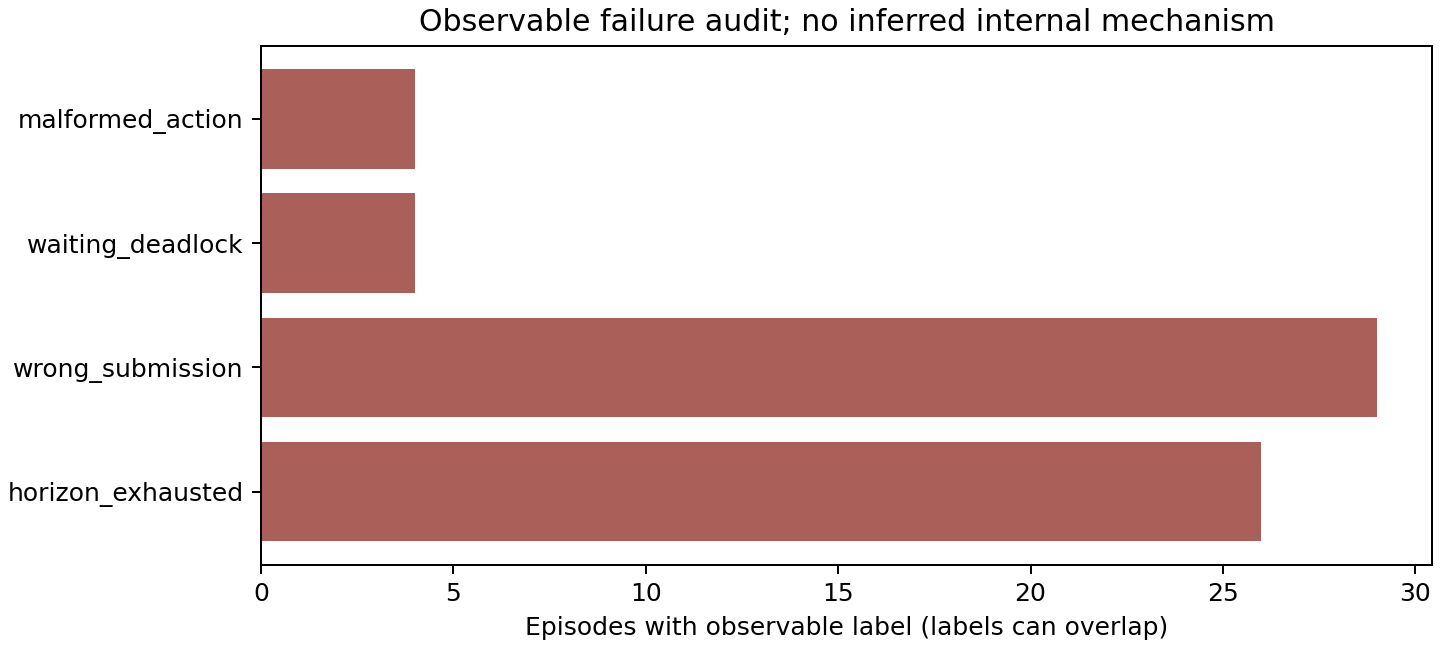

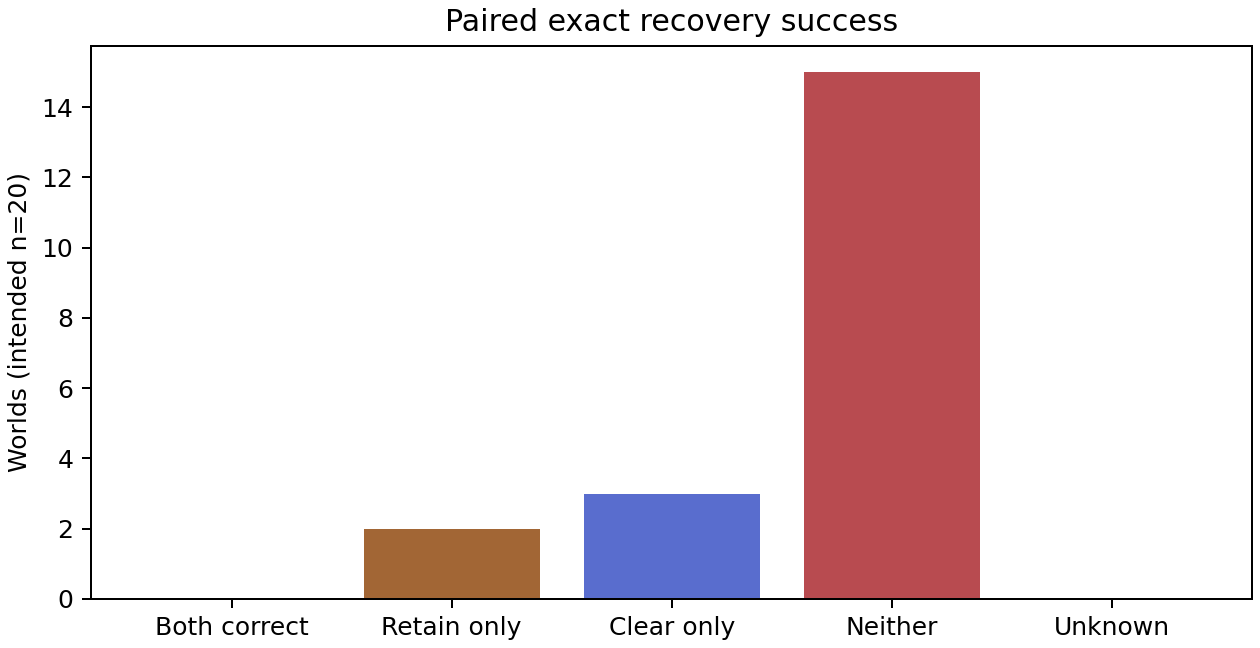

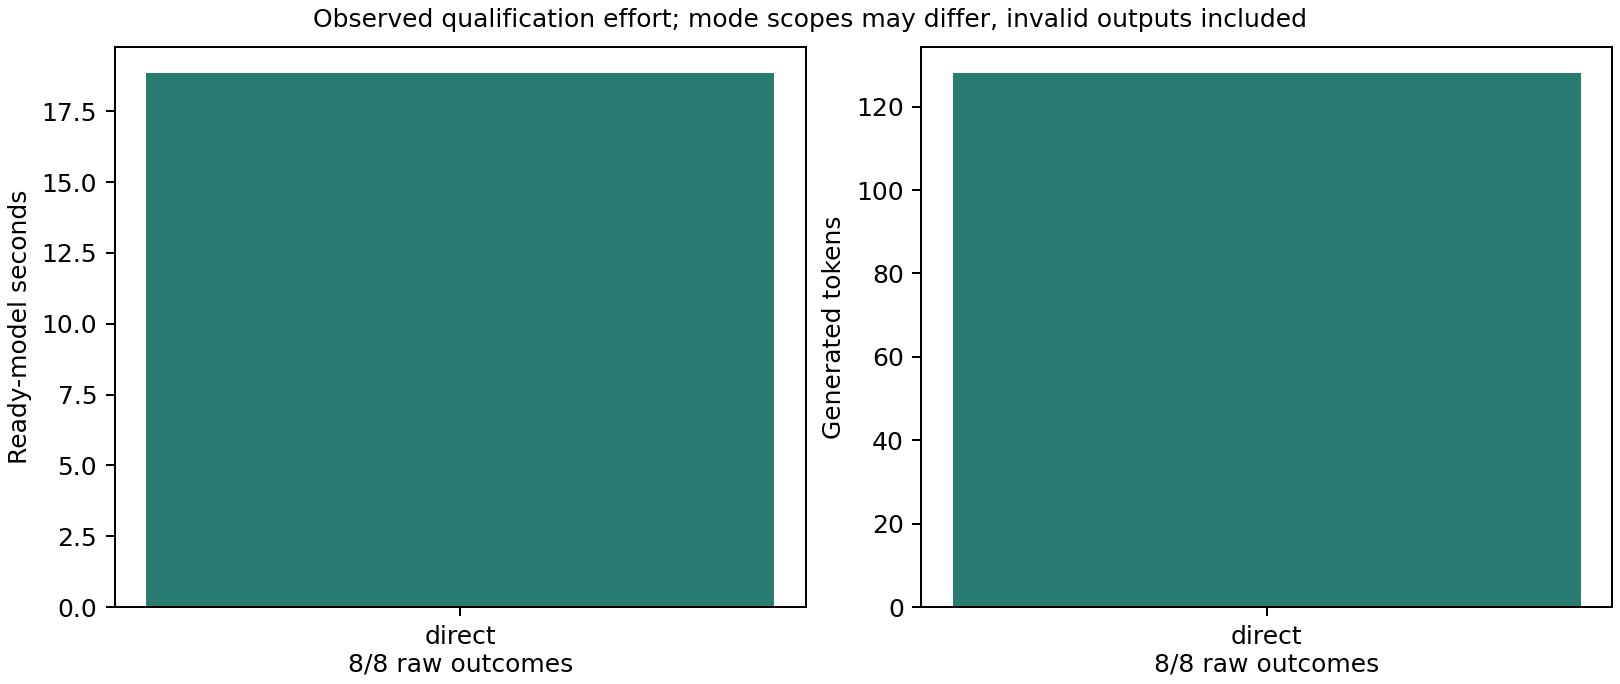

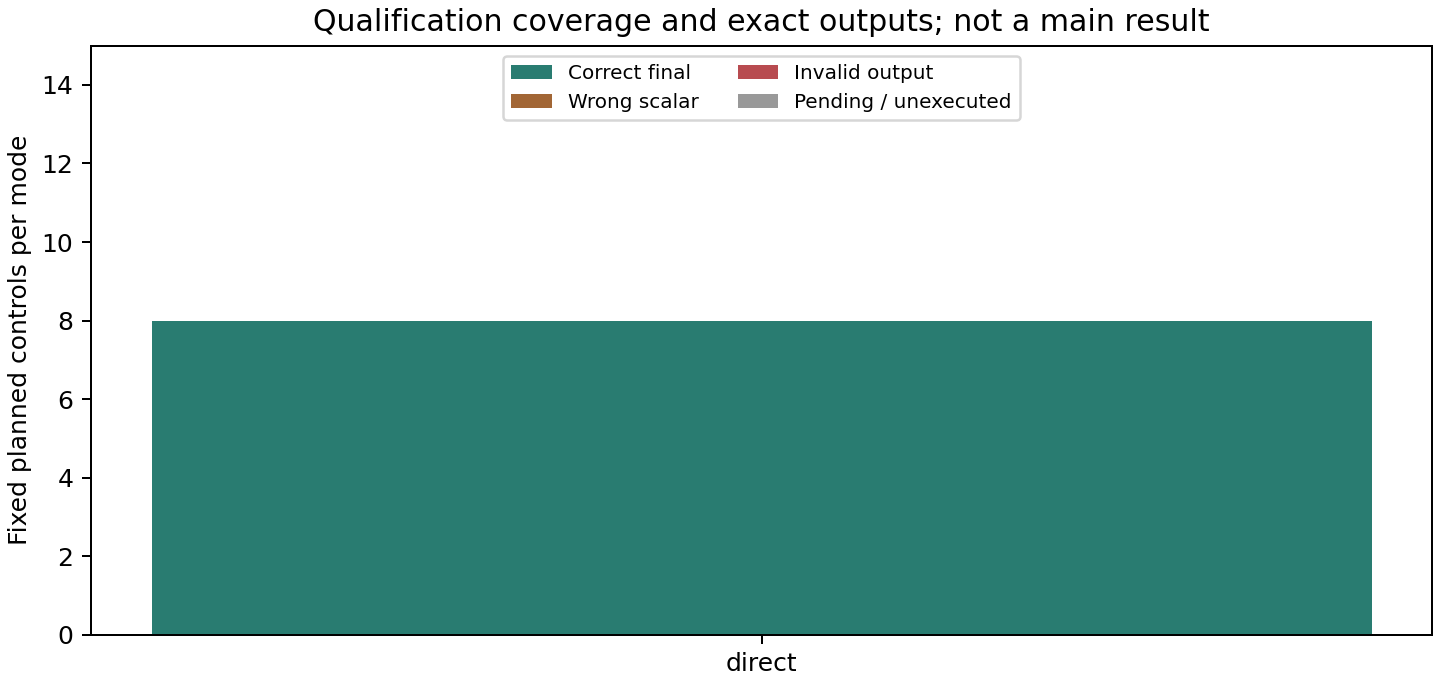

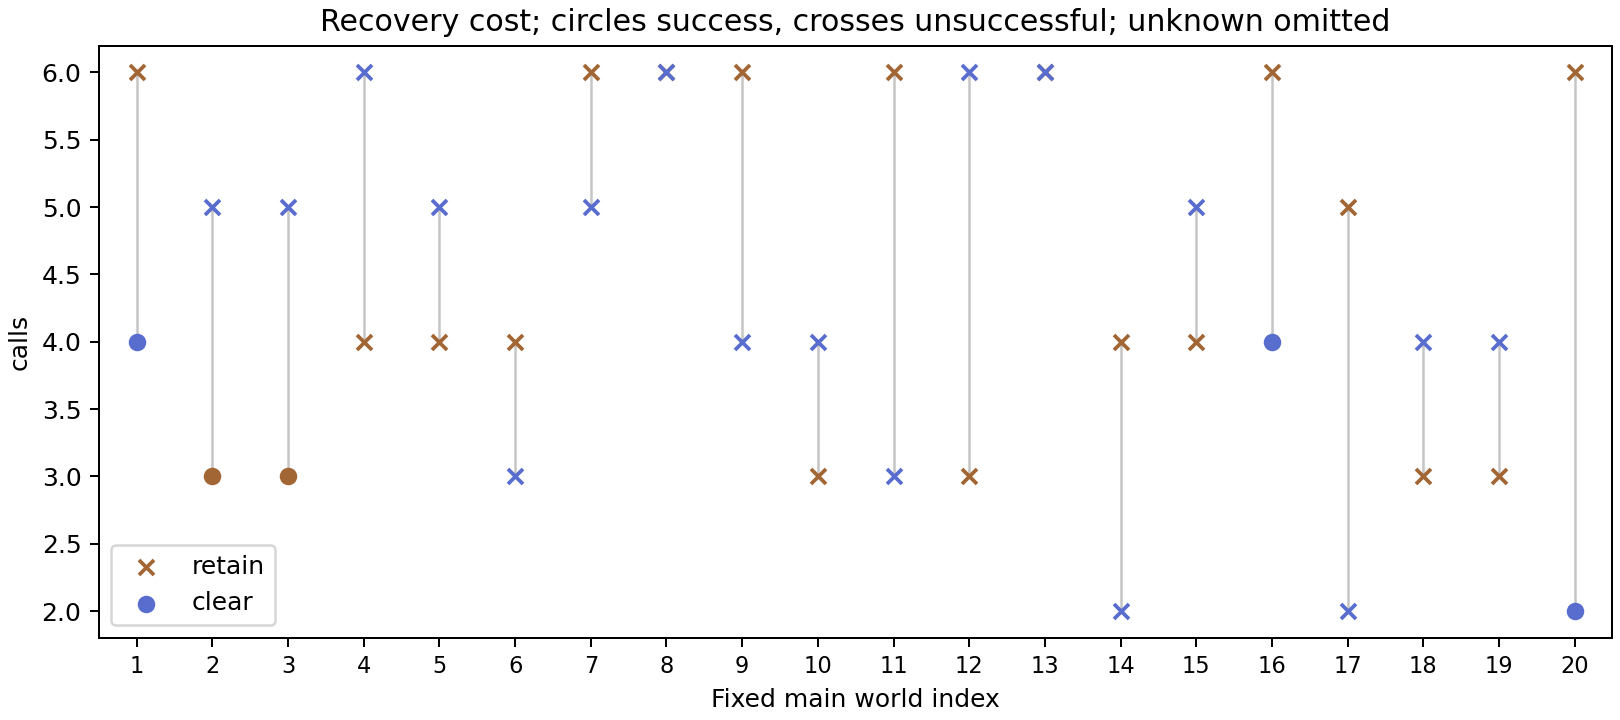

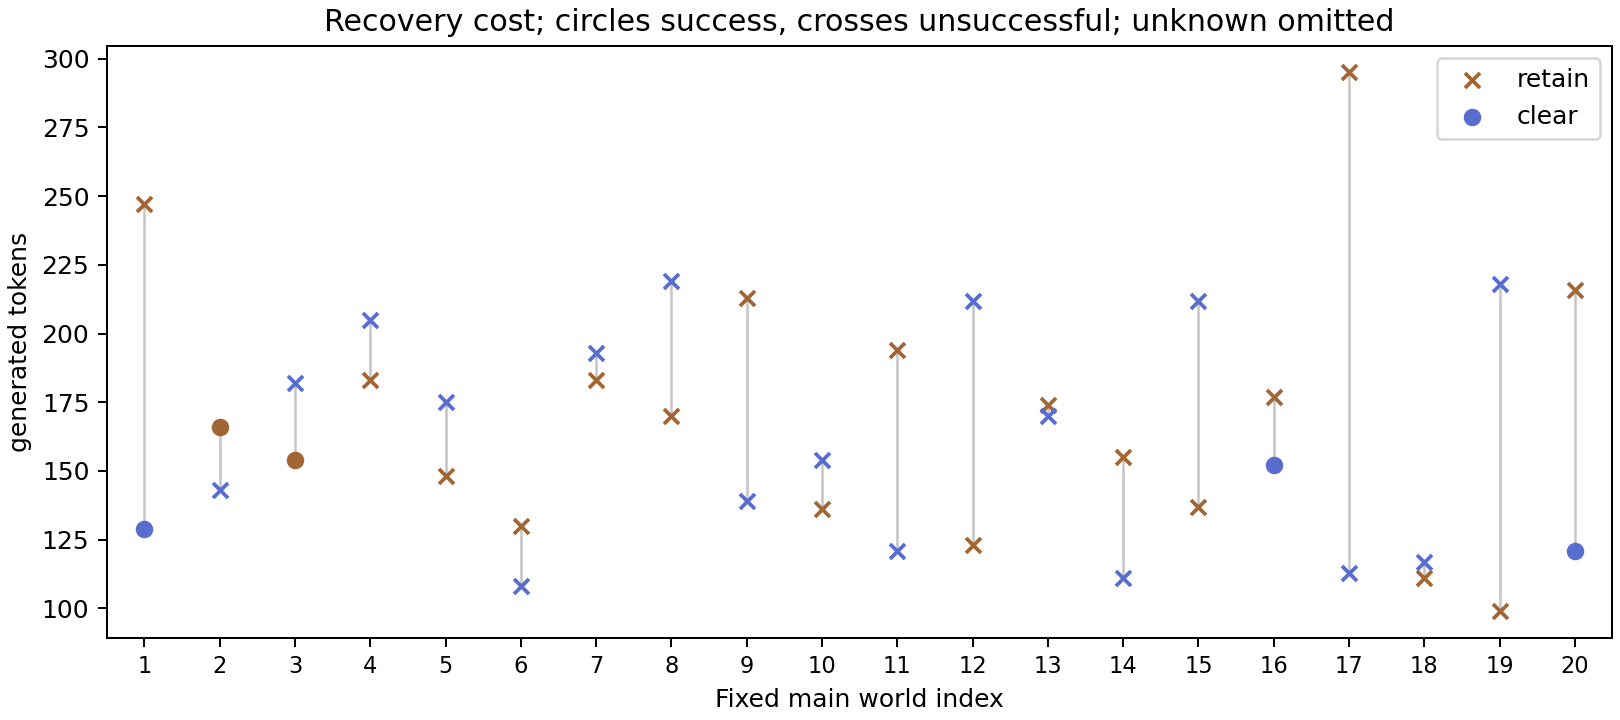

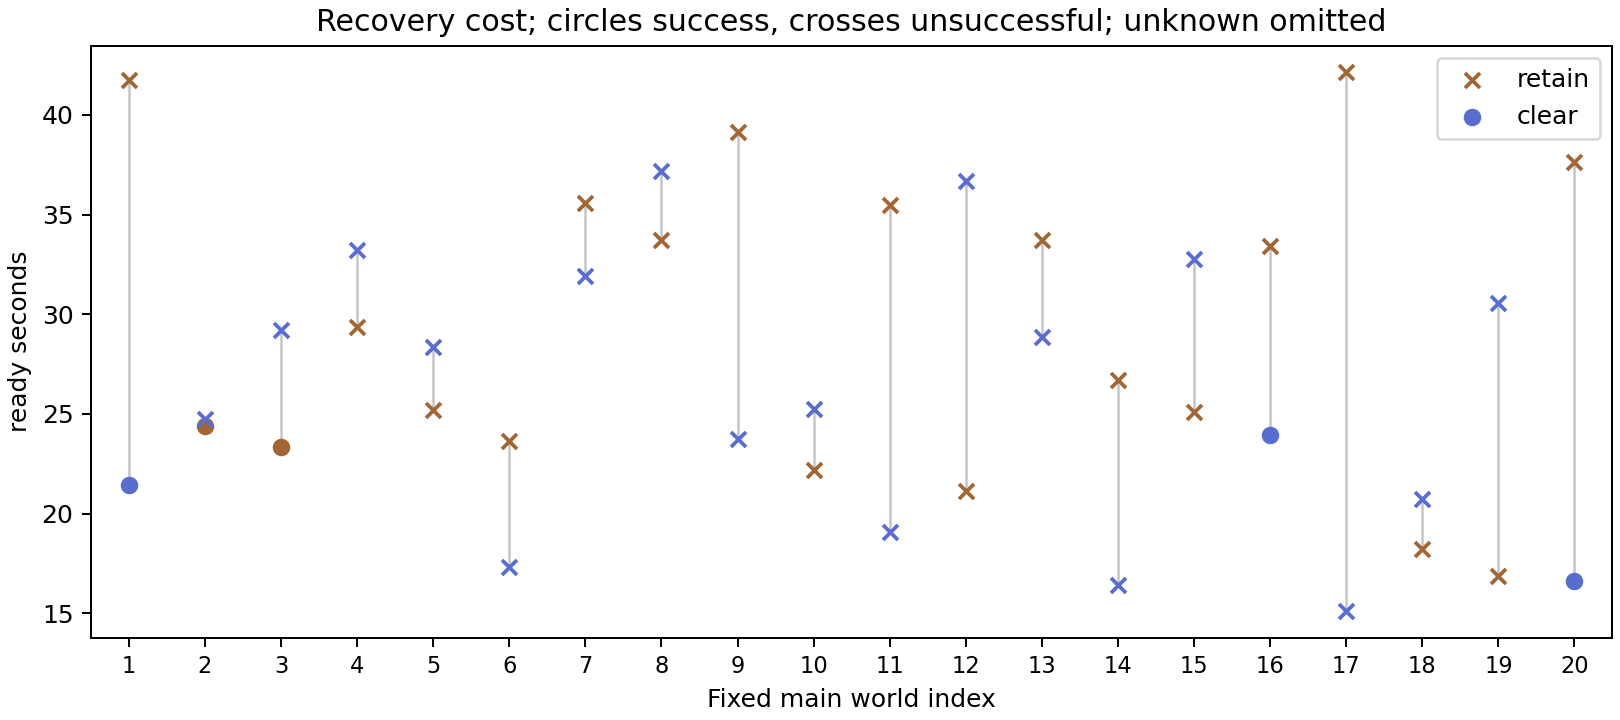

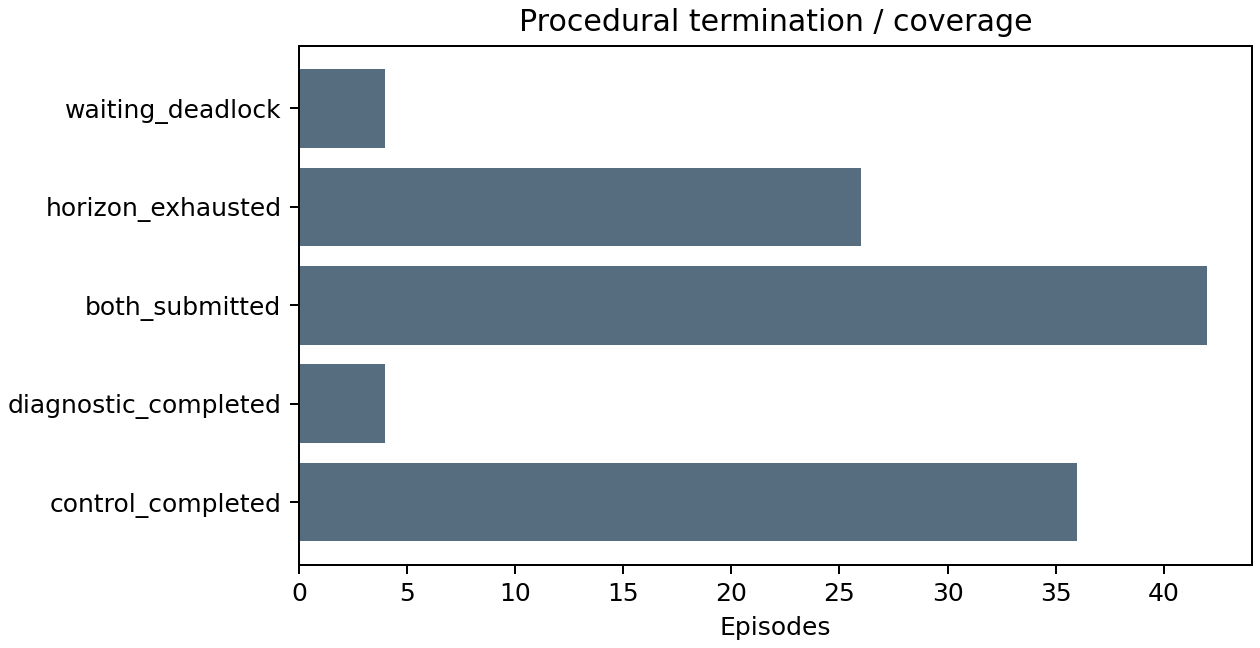

In [35]:
study.build_report();


## Verify the portable checkpoint and download results

Quiescent cumulative ZIP and exact read-only fresh-directory reconstruction. Download latest.zip and the executed notebook. Checkpoints happen automatically even if you ignore their links during execution.


In [36]:
study.save_checkpoint(verify=True);


Checkpoint action/snapshot: 4,128,802 bytes; integrity passed
snapshot: complete · checkpoint /kaggle/working/i01-assisted-study/exports/latest.zip


Measurement,Recorded value
Boundary requested,operator-snapshot


Checkpoint: passed


Measurement,Recorded value
Integrity,passed
Attempts,356
Boundary,action/snapshot
Reconstruction,exact outcomes/costs/traces/gates match archived analysis
Model attempts,0


## Close model workers and controller

Close after final export; the closing checkpoint retains actual process evidence. Stop Kaggle through its UI to release its allocation. Process closure and a link do not prove provider deallocation or an external download.


In [37]:
study.finish_session();


Checkpoint close-models: 4,129,796 bytes; integrity passed


Checkpoint controller-close: 4,129,815 bytes; integrity passed
Controller output closed; process exit is not yet confirmed


Measurement,Recorded value
Processes closed,Yes
Provider release,Stop Kaggle through its UI; process exit alone does not prove deallocation.


## Results, errors and later restoration

The cumulative checkpoint is **/kaggle/working/i01-assisted-study/exports/latest.zip**;
reports, all conversations/raw outcomes, CSV tables and figures are under
**/kaggle/working/i01-assisted-study/reports/**. Download them and the executed
notebook outside the session. Save existing output without another inference run.

A real prerequisite failure stops further admission, attempts a settled partial export, closes workers with recorded acknowledgements and keeps the last valid
archive plus receipts. A provider hard shutdown may occur before a new export;
no missing outcome or unbounded spending is silently assumed zero. Checkpoints
are already present; a convenient restore workflow can be added later without
having to reconstruct unsaved hours of work.

For inspection with intact files (copy only the needed commands into a cell):

    study.show_status();
    study.inspect(audit_limit=None);  # Every raw call, no display limit.
    study.links(all_files=True);
    study.build_report();  # Works read-only after controller closure.

Before closure, interrupt requests pause; wait for admitted calls to settle:

    study.pause();
    study.save_checkpoint(verify=True);
    study.finish_session();

For a later session, use this checkpoint's exact source and the existing explicit
restore/reopen commands in **docs/I01_KAGGLE.md**. Supply actual prior-exit/tail
and current-time facts. New loaded replicas require six current-load state checks and two envelopes, all charged to the 20-attempt reserve;
do not repeat completed controls, pilot outcomes or earlier numbered batches.
Do not rerun the complete notebook to bypass a failed gate or reset its budget.

After execution, inspect all pilot/main conversations and add genuine human
annotations using the frozen rubric and exact call references. Automatic checks
establish evidence/protocol/resource eligibility, not meaningful communication,
human understanding, download completion or a favorable scientific effect.
